<a href="https://colab.research.google.com/github/sastha-06/24ADI006_DL_24BAD106/blob/main/24BAD106_DL_Exp4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import tensorflow as tf
print("SASTHA JEYASRI A\n24BAD106")
print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices('GPU'))

SASTHA JEYASRI A
24BAD106
TensorFlow version: 2.20.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

print("TensorFlow:", tf.__version__)

TensorFlow: 2.20.0


In [3]:
from google.colab import files

uploaded = files.upload()

Saving archive_1.zip to archive_1.zip


In [4]:
import zipfile
import os

zip_file = list(uploaded.keys())[0]

with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall('/content/dataset')

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [8]:

print(os.listdir("/content/dataset"))

['val.csv', 'train.csv', 'val', 'train']


In [9]:
# Get uploaded ZIP filename
zip_file = list(uploaded.keys())[0]

# Extract dataset
EXTRACT_DIR = "/content/dataset"

# Remove old dataset if it exists
if os.path.exists(EXTRACT_DIR):
    shutil.rmtree(EXTRACT_DIR)

os.makedirs(EXTRACT_DIR, exist_ok=True)

with zipfile.ZipFile(zip_file, "r") as zip_ref:
    zip_ref.extractall(EXTRACT_DIR)

print("Dataset extracted successfully!")
print("\nContents of dataset:")

for item in os.listdir(EXTRACT_DIR):
    print("-", item)

Dataset extracted successfully!

Contents of dataset:
- val.csv
- train.csv
- val
- train


In [10]:
print("Train folders:")
print(os.listdir("/content/dataset/train"))

print("\nValidation folders:")
print(os.listdir("/content/dataset/val"))

Train folders:
['classname.txt', 'cat', 'dog']

Validation folders:
['classname.txt', 'cat', 'dog']



Train folders:
['classname.txt', 'cat', 'dog']

Validation folders:
['classname.txt', 'cat', 'dog']

Train Dataset
cat: 95 images
dog: 180 images

Validation Dataset
cat: 24 images
dog: 46 images

Test cat: 4 images

Test dog: 9 images

Test dataset created!
Found 275 files belonging to 2 classes.
Found 70 files belonging to 2 classes.
Found 13 files belonging to 2 classes.

Classes: ['cat', 'dog']


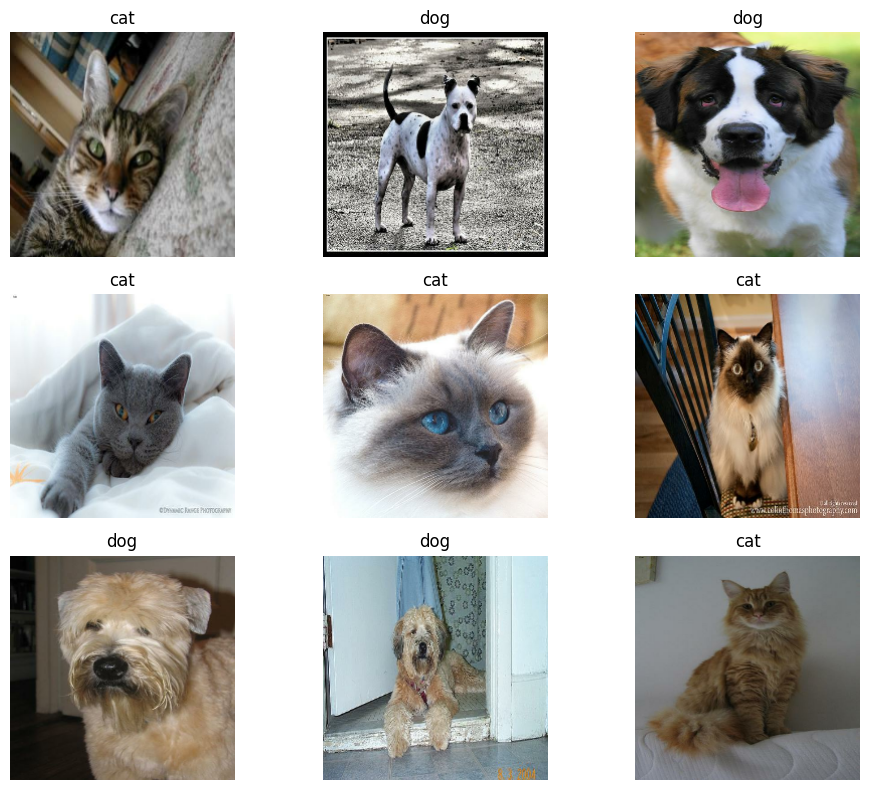

Dataset preparation completed!
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step

ResNet-50 model created!


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ ?                      │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,587,712 (89.98 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 23,587,712 (89.98 MB)


Starting ResNet-50 training...
Epoch 1/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 18s 652ms/step - accuracy: 0.7855 - loss: 0.5027 - val_accuracy: 0.8857 - val_loss: 0.2852
Epoch 2/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 173ms/step - accuracy: 0.9600 - loss: 0.1012 - val_accuracy: 0.9857 - val_loss: 0.0396
Epoch 3/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 164ms/step - accuracy: 0.9709 - loss: 0.0590 - val_accuracy: 0.9571 - val_loss: 0.1081
Epoch 4/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 3s 163ms/step - accuracy: 0.9927 - loss: 0.0175 - val_accuracy: 0.9857 - val_loss: 0.0301
Epoch 5/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 164ms/step - accuracy: 0.9964 - loss: 0.0177 - val_accuracy: 0.9857 - val_loss: 0.0344
Epoch 6/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 164ms/step - accuracy: 0.9891 - loss: 0.0195 - val_accuracy: 0.9857 - val_loss: 0.0436
Epoch 7/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 162ms/step - accuracy: 1.0000 - loss: 0.0046 - val_accuracy: 0.9857 - val_loss: 0.0195
Epoch 8/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 175ms/step - accuracy: 1.0000 - loss: 0.0041 -

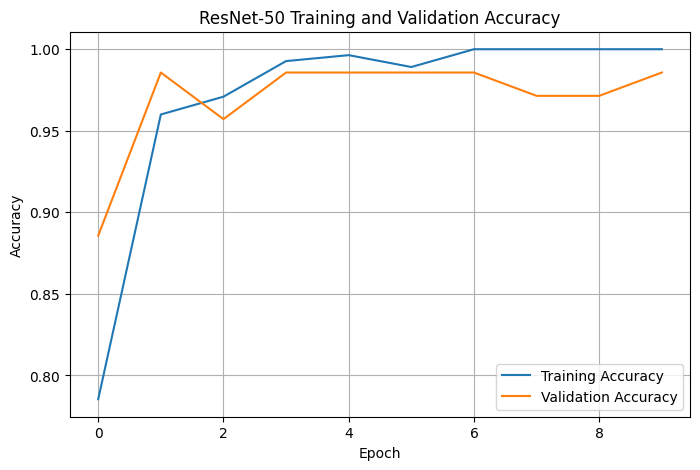

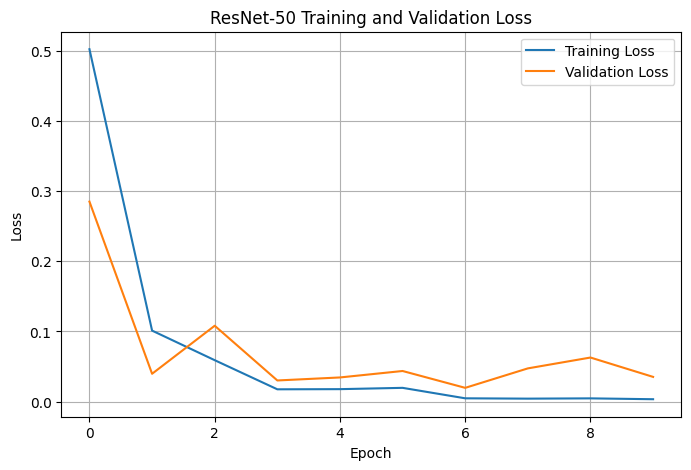


FINAL TRAINING RESULTS
Training Accuracy   : 100.00%
Validation Accuracy : 98.57%
Test Accuracy       : 100.00%
Training Loss       : 0.0033
Validation Loss     : 0.0352
Test Loss           : 0.0002

Loading Hugging Face ViT...


config.json:   0%|          | 0.00/69.7k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

Hugging Face ViT loaded successfully!

Upload a sample cat or dog image


Saving WhatsApp Image 2026-08-17 at 1.22.40 PM.jpeg to WhatsApp Image 2026-08-17 at 1.22.40 PM.jpeg


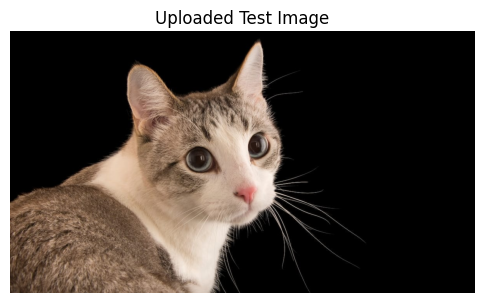


HUGGING FACE ViT PREDICTIONS
Egyptian cat : 80.86%
tiger cat : 7.97%
tabby, tabby cat : 7.48%
lynx, catamount : 0.47%
Siamese cat, Siamese : 0.39%

RESNET-50 PREDICTION
Predicted Class : cat
Confidence      : 100.00%

Class Probabilities:
cat: 100.00%
dog: 0.00%


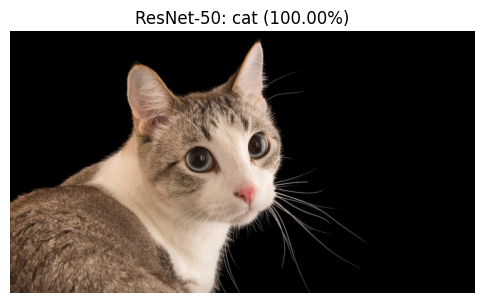



FINAL PROJECT SUMMARY

Model: ResNet-50 Transfer Learning
Classes: ['cat', 'dog']
Epochs: 10
Test Accuracy: 100.00%

Uploaded Image Result:
ResNet-50 Prediction: cat
ResNet-50 Confidence: 100.00%

Hugging Face ViT Top Prediction: Egyptian cat
Hugging Face ViT Confidence: 80.86%

PROJECT COMPLETED SUCCESSFULLY!


In [11]:
import os
import shutil
import random
import zipfile
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from PIL import Image
from google.colab import files

# -------------------- PARAMETERS --------------------
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42
EPOCHS = 10

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

DATASET_DIR = "/content/dataset"
TRAIN_DIR = "/content/dataset/train"
VAL_DIR = "/content/dataset/val"
TEST_DIR = "/content/test_dataset"

CLASSES = ["cat", "dog"]

# ============================================================
# 2. CHECK DATASET STRUCTURE
# ============================================================

print("\nTrain folders:")
print(os.listdir(TRAIN_DIR))

print("\nValidation folders:")
print(os.listdir(VAL_DIR))

# Check class folders
for split_name, split_dir in [
    ("Train", TRAIN_DIR),
    ("Validation", VAL_DIR)
]:

    print(f"\n{split_name} Dataset")

    for class_name in CLASSES:

        class_path = os.path.join(
            split_dir,
            class_name
        )

        if not os.path.exists(class_path):
            raise FileNotFoundError(
                f"Missing folder: {class_path}"
            )

        images = [
            f for f in os.listdir(class_path)
            if f.lower().endswith(
                (".jpg", ".jpeg", ".png")
            )
        ]

        print(
            f"{class_name}: {len(images)} images"
        )

# ============================================================
# 3. CREATE TEST DATASET
# ============================================================
# The dataset already has train and validation.
# We take 20% of validation images as a separate test set.

if os.path.exists(TEST_DIR):
    shutil.rmtree(TEST_DIR)

for class_name in CLASSES:

    os.makedirs(
        os.path.join(
            TEST_DIR,
            class_name
        ),
        exist_ok=True
    )

random.seed(SEED)

for class_name in CLASSES:

    source_path = os.path.join(
        VAL_DIR,
        class_name
    )

    test_path = os.path.join(
        TEST_DIR,
        class_name
    )

    images = [
        f for f in os.listdir(source_path)
        if f.lower().endswith(
            (".jpg", ".jpeg", ".png")
        )
    ]

    random.shuffle(images)

    test_count = int(
        0.20 * len(images)
    )

    test_images = images[:test_count]

    for image in test_images:

        shutil.copy(
            os.path.join(
                source_path,
                image
            ),
            os.path.join(
                test_path,
                image
            )
        )

    print(
        f"\nTest {class_name}: "
        f"{len(test_images)} images"
    )

print("\nTest dataset created!")

# ============================================================
# 4. LOAD DATASETS
# ============================================================

train_ds = tf.keras.utils.image_dataset_from_directory(

    TRAIN_DIR,

    image_size=IMG_SIZE,

    batch_size=BATCH_SIZE,

    shuffle=True,

    seed=SEED,

    class_names=CLASSES
)

val_ds = tf.keras.utils.image_dataset_from_directory(

    VAL_DIR,

    image_size=IMG_SIZE,

    batch_size=BATCH_SIZE,

    shuffle=False,

    class_names=CLASSES
)

test_ds = tf.keras.utils.image_dataset_from_directory(

    TEST_DIR,

    image_size=IMG_SIZE,

    batch_size=BATCH_SIZE,

    shuffle=False,

    class_names=CLASSES
)

class_names = train_ds.class_names

print("\nClasses:", class_names)

# ============================================================
# 5. DISPLAY SAMPLE IMAGES
# ============================================================

plt.figure(figsize=(10, 8))

for images, labels in train_ds.take(1):

    for i in range(
        min(9, len(images))
    ):

        plt.subplot(
            3,
            3,
            i + 1
        )

        plt.imshow(
            images[i].numpy().astype("uint8")
        )

        plt.title(
            class_names[labels[i]]
        )

        plt.axis("off")

plt.tight_layout()
plt.show()

# ============================================================
# 6. OPTIMIZE DATA LOADING
# ============================================================

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(
    AUTOTUNE
)

val_ds = val_ds.prefetch(
    AUTOTUNE
)

test_ds = test_ds.prefetch(
    AUTOTUNE
)

print("Dataset preparation completed!")

# ============================================================
# 7. IMPORT RESNET-50
# ============================================================

from tensorflow.keras.applications import ResNet50

from tensorflow.keras.applications.resnet50 import (
    preprocess_input
)

from tensorflow.keras import (
    layers,
    models
)

# ============================================================
# 8. DATA AUGMENTATION
# ============================================================

data_augmentation = tf.keras.Sequential([

    layers.RandomFlip(
        "horizontal"
    ),

    layers.RandomRotation(
        0.1
    ),

    layers.RandomZoom(
        0.1
    )
])

# ============================================================
# 9. LOAD PRE-TRAINED RESNET-50
# ============================================================

base_model = ResNet50(

    weights="imagenet",

    include_top=False,

    input_shape=(
        224,
        224,
        3
    )
)

# Freeze pre-trained layers
base_model.trainable = False

# ============================================================
# 10. BUILD TRANSFER LEARNING MODEL
# ============================================================

model = models.Sequential([

    data_augmentation,

    layers.Lambda(
        preprocess_input
    ),

    base_model,

    layers.GlobalAveragePooling2D(),

    layers.Dense(
        128,
        activation="relu"
    ),

    layers.Dropout(
        0.3
    ),

    layers.Dense(
        len(class_names),
        activation="softmax"
    )
])

print("\nResNet-50 model created!")

# ============================================================
# 11. COMPILE MODEL
# ============================================================

model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]
)

model.summary()

# ============================================================
# 12. TRAIN MODEL
# ============================================================

print("\nStarting ResNet-50 training...")

history = model.fit(

    train_ds,

    validation_data=val_ds,

    epochs=EPOCHS
)

print("\nTraining completed!")

# ============================================================
# 13. TEST MODEL
# ============================================================

test_loss, test_accuracy = model.evaluate(
    test_ds
)

print("\n==============================")
print("RESNET-50 TEST RESULTS")
print("==============================")

print(
    "Test Loss:",
    f"{test_loss:.4f}"
)

print(
    "Test Accuracy:",
    f"{test_accuracy * 100:.2f}%"
)

# ============================================================
# 14. ACCURACY GRAPH
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.title(
    "ResNet-50 Training and Validation Accuracy"
)

plt.legend()
plt.grid(True)

plt.show()

# ============================================================
# 15. LOSS GRAPH
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "ResNet-50 Training and Validation Loss"
)

plt.legend()
plt.grid(True)

plt.show()

# ============================================================
# 16. FINAL TRAINING RESULTS
# ============================================================

print("\n==============================")
print("FINAL TRAINING RESULTS")
print("==============================")

print(
    "Training Accuracy   :",
    f"{history.history['accuracy'][-1] * 100:.2f}%"
)

print(
    "Validation Accuracy :",
    f"{history.history['val_accuracy'][-1] * 100:.2f}%"
)

print(
    "Test Accuracy       :",
    f"{test_accuracy * 100:.2f}%"
)

print(
    "Training Loss       :",
    f"{history.history['loss'][-1]:.4f}"
)

print(
    "Validation Loss     :",
    f"{history.history['val_loss'][-1]:.4f}"
)

print(
    "Test Loss           :",
    f"{test_loss:.4f}"
)

# ============================================================
# 17. INSTALL HUGGING FACE TRANSFORMERS
# ============================================================

!pip install -q transformers

# ============================================================
# 18. LOAD HUGGING FACE VISION TRANSFORMER
# ============================================================

from transformers import pipeline

print("\nLoading Hugging Face ViT...")

classifier = pipeline(
    "image-classification",
    model="google/vit-base-patch16-224"
)

print(
    "Hugging Face ViT loaded successfully!"
)

# ============================================================
# 19. UPLOAD SAMPLE IMAGE FOR PREDICTION
# ============================================================

print("\nUpload a sample cat or dog image")

uploaded_image = files.upload()

image_path = list(
    uploaded_image.keys()
)[0]

image = Image.open(
    image_path
).convert("RGB")

# Display image
plt.figure(figsize=(6, 6))

plt.imshow(image)

plt.axis("off")

plt.title(
    "Uploaded Test Image"
)

plt.show()

# ============================================================
# 20. HUGGING FACE PREDICTION
# ============================================================

results = classifier(image)

print("\n==============================")
print("HUGGING FACE ViT PREDICTIONS")
print("==============================")

for result in results[:5]:

    print(
        f"{result['label']} : "
        f"{result['score'] * 100:.2f}%"
    )

# ============================================================
# 21. RESNET-50 PREDICTION
# ============================================================

img = tf.keras.utils.load_img(

    image_path,

    target_size=IMG_SIZE
)

img_array = tf.keras.utils.img_to_array(
    img
)

img_array = tf.expand_dims(
    img_array,
    0
)

prediction = model.predict(
    img_array,
    verbose=0
)

predicted_index = np.argmax(
    prediction[0]
)

predicted_class = class_names[
    predicted_index
]

confidence = (
    prediction[0][predicted_index]
    * 100
)

# ============================================================
# 22. DISPLAY RESNET-50 PREDICTION
# ============================================================

print("\n==============================")
print("RESNET-50 PREDICTION")
print("==============================")

print(
    "Predicted Class :",
    predicted_class
)

print(
    "Confidence      :",
    f"{confidence:.2f}%"
)

print("\nClass Probabilities:")

for i, class_name in enumerate(
    class_names
):

    print(
        f"{class_name}: "
        f"{prediction[0][i] * 100:.2f}%"
    )

# ============================================================
# 23. DISPLAY FINAL PREDICTION
# ============================================================

plt.figure(figsize=(6, 6))

plt.imshow(image)

plt.axis("off")

plt.title(
    f"ResNet-50: {predicted_class} "
    f"({confidence:.2f}%)"
)

plt.show()

# ============================================================
# 24. FINAL SUMMARY
# ============================================================

print("\n")
print("=" * 60)
print("FINAL PROJECT SUMMARY")
print("=" * 60)

print(
    "\nModel: ResNet-50 Transfer Learning"
)

print(
    "Classes:",
    class_names
)

print(
    "Epochs:",
    EPOCHS
)

print(
    "Test Accuracy:",
    f"{test_accuracy * 100:.2f}%"
)

print(
    "\nUploaded Image Result:"
)

print(
    "ResNet-50 Prediction:",
    predicted_class
)

print(
    "ResNet-50 Confidence:",
    f"{confidence:.2f}%"
)

print(
    "\nHugging Face ViT Top Prediction:",
    results[0]["label"]
)

print(
    "Hugging Face ViT Confidence:",
    f"{results[0]['score'] * 100:.2f}%"
)

print("\n" + "=" * 60)
print("PROJECT COMPLETED SUCCESSFULLY!")
print("=" * 60)